# Hands-on 36: Studi Kasus B - Predictive Maintenance Sederhana

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 14.

Data getaran + arus motor dengan fase normal -> warning -> fault. Fitur diekstrak per
jendela (mean/std/RMS/peak-to-peak), lalu Isolation Forest untuk anomali dan Random
Forest untuk klasifikasi status.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Generate Data Motor

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/case_b_generate_motor_data.py"], capture_output=True, text=True)
print(r.stdout)

Disimpan ke: data/synthetic/case_b_motor.csv



## 2. Ekstraksi Fitur per Jendela

In [3]:
r = subprocess.run([sys.executable, "scripts/case_b_feature_window.py"], capture_output=True, text=True)
print(r.stdout)

Disimpan ke: data/processed/case_b_motor_features.csv



## 3. Anomaly Detection + Klasifikasi

In [4]:
r = subprocess.run([sys.executable, "scripts/case_b_detect_and_classify.py"], capture_output=True, text=True)
print(r.stdout)

=== Isolation Forest ===
anomaly_pred
0    101
1     18
Name: count, dtype: int64

=== Fault Classification ===
[[15  0  0]
 [ 0  0  0]
 [ 0  0  9]]
              precision    recall  f1-score   support

       fault       1.00      1.00      1.00         9
      normal       1.00      1.00      1.00        15

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24




## 4. Visualisasi Sinyal per Fase

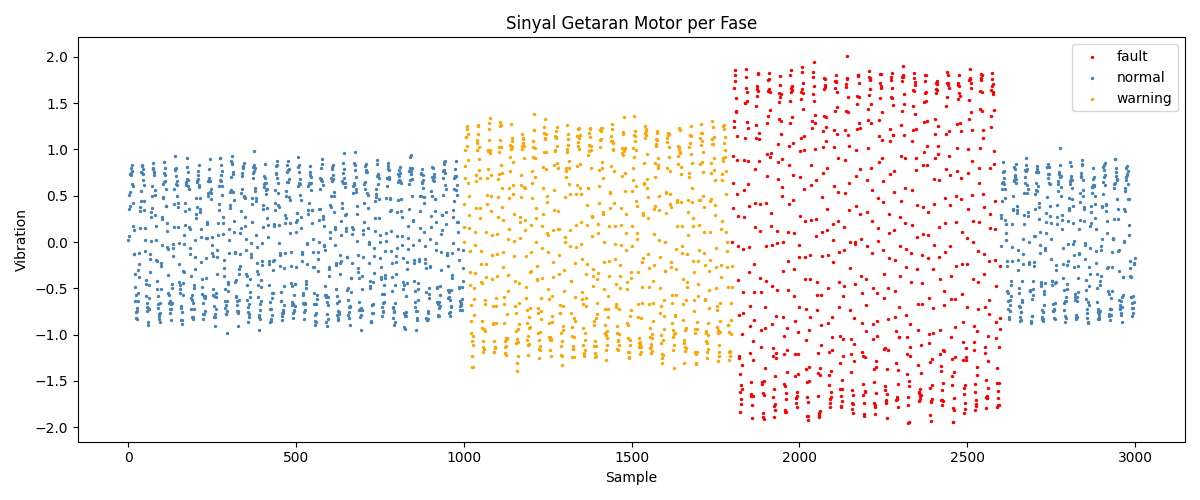

In [5]:
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

df = pd.read_csv("data/synthetic/case_b_motor.csv")
colors = {"normal": "steelblue", "warning": "orange", "fault": "red"}
plt.figure(figsize=(12, 5))
for status, grp in df.groupby("status_label"):
    plt.scatter(grp["sample_id"], grp["vibration"], s=2, label=status, color=colors[status])
plt.title("Sinyal Getaran Motor per Fase")
plt.xlabel("Sample")
plt.ylabel("Vibration")
plt.legend()
plt.tight_layout()
plt.savefig("outputs/figures/case_b_vibration_phases.png")
plt.close()
from IPython.display import Image
Image("outputs/figures/case_b_vibration_phases.png")

## Penutup

Fase warning dan fault terlihat jelas dari amplitudo getaran dan arus yang naik.
Isolation Forest menandai 18 dari 119 jendela sebagai anomali (sekitar 15%, sesuai
contamination), dan Random Forest memisahkan normal vs fault dengan sempurna pada
test time-aware. Cocok untuk motor kecil, pompa, blower, dan alat lab.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 38 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 6. Evaluasi

Untuk anomaly detection:
- confusion matrix bila ground truth sintetis ada
- precision / recall terhadap anomali
Untuk klasifikasi:
- accuracy
- recall untuk fault
- confusion matrix

### 7. Interpretasi hasil

Interpretasi yang baik harus menjawab:

apakah RMS naik?
apakah current_mean ikut naik?
apakah spike makin sering?
fitur mana yang paling berpengaruh?